# CDC HDP-proxy · признаки и одномерные связи

Воспроизводимая случайная 5% подвыборка общей когорты выбирается **без учёта метки и фолда**. Корреляции между признаками проверяют дублирование; для связи с бинарной меткой показаны прежде всего частоты по категориям и не скорректированные отношения шансов с 95% интервалом. Эти показатели описательные и не доказывают причинного влияния.

In [ ]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
from src.data.preeclampsia_cdc import OUT, ENRICHED_FEATURES
from src.evaluation.preeclampsia_cdc_features import analysis_sample

In [3]:
sample = analysis_sample(fraction=.05)
print(f"n={len(sample):,}, events={int(sample.target_hdp_proxy.sum()):,}, frequency={sample.target_hdp_proxy.mean():.4f}")
display(sample.groupby(["source_year","fold"]).target_hdp_proxy.agg(["size","sum","mean"]).round(4))

n=337,861, events=36,017, frequency=0.1066


size   sum    mean
source_year fold                     
2023        0     33929  3628  0.1069
            1     33911  3550  0.1047
            2     33516  3452  0.1030
            3     33748  3520  0.1043
            4     33467  3546  0.1060
2024        0     33885  3575  0.1055
            1     33635  3611  0.1074
            2     33821  3646  0.1078
            3     33876  3696  0.1091
            4     34073  3793  0.1113

## Корреляции самих признаков

,mager,bmi,prior_live_birth_count_cat,priorterm,rf_pdiab,rf_ppterm,rf_cesar,bmi_missing,prior_live_birth_count_missing,priorterm_missing,no_prior_live_birth,age_35_plus,bmi_30_plus,bmi_35_plus
mager,1.000,0.040,0.320,0.171,0.035,0.051,0.158,-0.003,0.004,0.004,-0.282,0.702,0.011,0.000
bmi,0.040,1.000,0.110,0.057,0.068,0.027,0.116,NaN,0.001,-0.001,-0.096,0.011,0.800,0.599
prior_live_birth_count_cat,0.320,0.110,1.000,0.199,0.016,0.188,0.307,0.019,NaN,0.013,-0.897,0.204,0.085,0.056
priorterm,0.171,0.057,0.199,1.000,0.020,0.089,0.078,-0.006,0.021,NaN,-0.172,0.129,0.046,0.035
rf_pdiab,0.035,0.068,0.016,0.020,1.000,0.033,0.034,-0.004,-0.000,0.001,-0.013,0.031,0.064,0.063
rf_ppterm,0.051,0.027,0.188,0.089,0.033,1.000,0.127,0.003,0.000,-0.002,-0.162,0.035,0.027,0.019
rf_cesar,0.158,0.116,0.307,0.078,0.034,0.127,1.000,0.001,-0.001,-0.002,-0.346,0.112,0.096,0.080
bmi_missing,-0.003,NaN,0.019,-0.006,-0.004,0.003,0.001,1.000,0.053,0.050,-0.010,0.005,NaN,NaN
prior_live_birth_count_missing,0.004,0.001,NaN,0.021,-0.000,0.000,-0.001,0.053,1.000,0.567,NaN,0.004,0.001,0.001
priorterm_missing,0.004,-0.001,0.013,NaN,0.001,-0.002,-0.002,0.050,0.567,1.000,-0.012,0.002,-0.000,-0.003


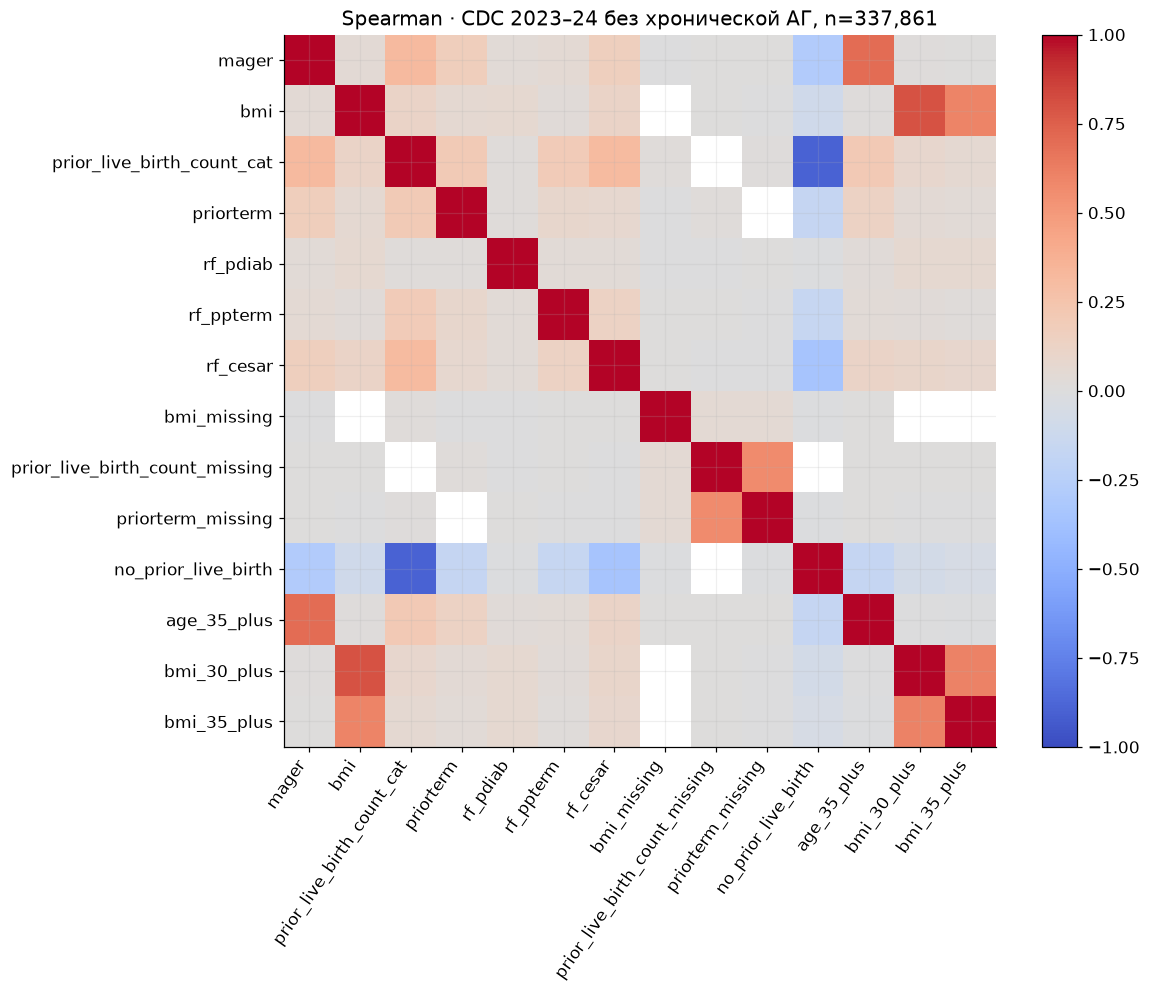

In [5]:
corr = sample[ENRICHED_FEATURES].corr(method="spearman")
display(corr.round(3))
fig, ax = plt.subplots(figsize=(11,9))
im = ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(corr)),corr.columns,rotation=55,ha="right")
ax.set_yticks(range(len(corr)),corr.index)
ax.set(title=f"Spearman · CDC 2023–24 без хронической АГ, n={len(sample):,}")
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## Частоты по клинически понятным категориям

,n,events,event_rate,variable
mager,,,,
"(9, 19]",13636,1405,0.1030,age
"(19, 24]",58622,6166,0.1052,age
"(24, 29]",93002,9931,0.1068,age
"(29, 34]",102870,10654,0.1036,age
"(34, 39]",56443,6102,0.1081,age
"(39, 44]",12395,1617,0.1305,age
"(44, 55]",893,142,0.1590,age


,n,events,event_rate,variable
bmi,,,,
"(12.9, 18.5]",9582,507,0.0529,bmi
"(18.5, 25.0]",128777,8833,0.0686,bmi
"(25.0, 30.0]",92563,9329,0.1008,bmi
"(30.0, 35.0]",54069,7516,0.1390,bmi
"(35.0, 40.0]",26874,4810,0.1790,bmi
"(40.0, 70.0]",18329,4296,0.2344,bmi


,n,events,event_rate,variable
prior_live_birth_count_cat,,,,
-1.0,980,93,0.0949,prior_live_births
0.0,136523,18446,0.1351,prior_live_births
1.0,104034,9200,0.0884,prior_live_births
2.0,54440,4602,0.0845,prior_live_births
3.0,41884,3676,0.0878,prior_live_births


,n,events,event_rate,variable
rf_pdiab,,,,
0.0,334242,35119,0.1051,pregestational_diabetes
1.0,3619,898,0.2481,pregestational_diabetes


,n,events,event_rate,variable
ART_no,320138,33838,0.1057,ART_reporting_state
ART_yes,5832,885,0.1517,ART_reporting_state
not_reported,11691,1260,0.1078,ART_reporting_state
unknown_reported,200,34,0.1700,ART_reporting_state


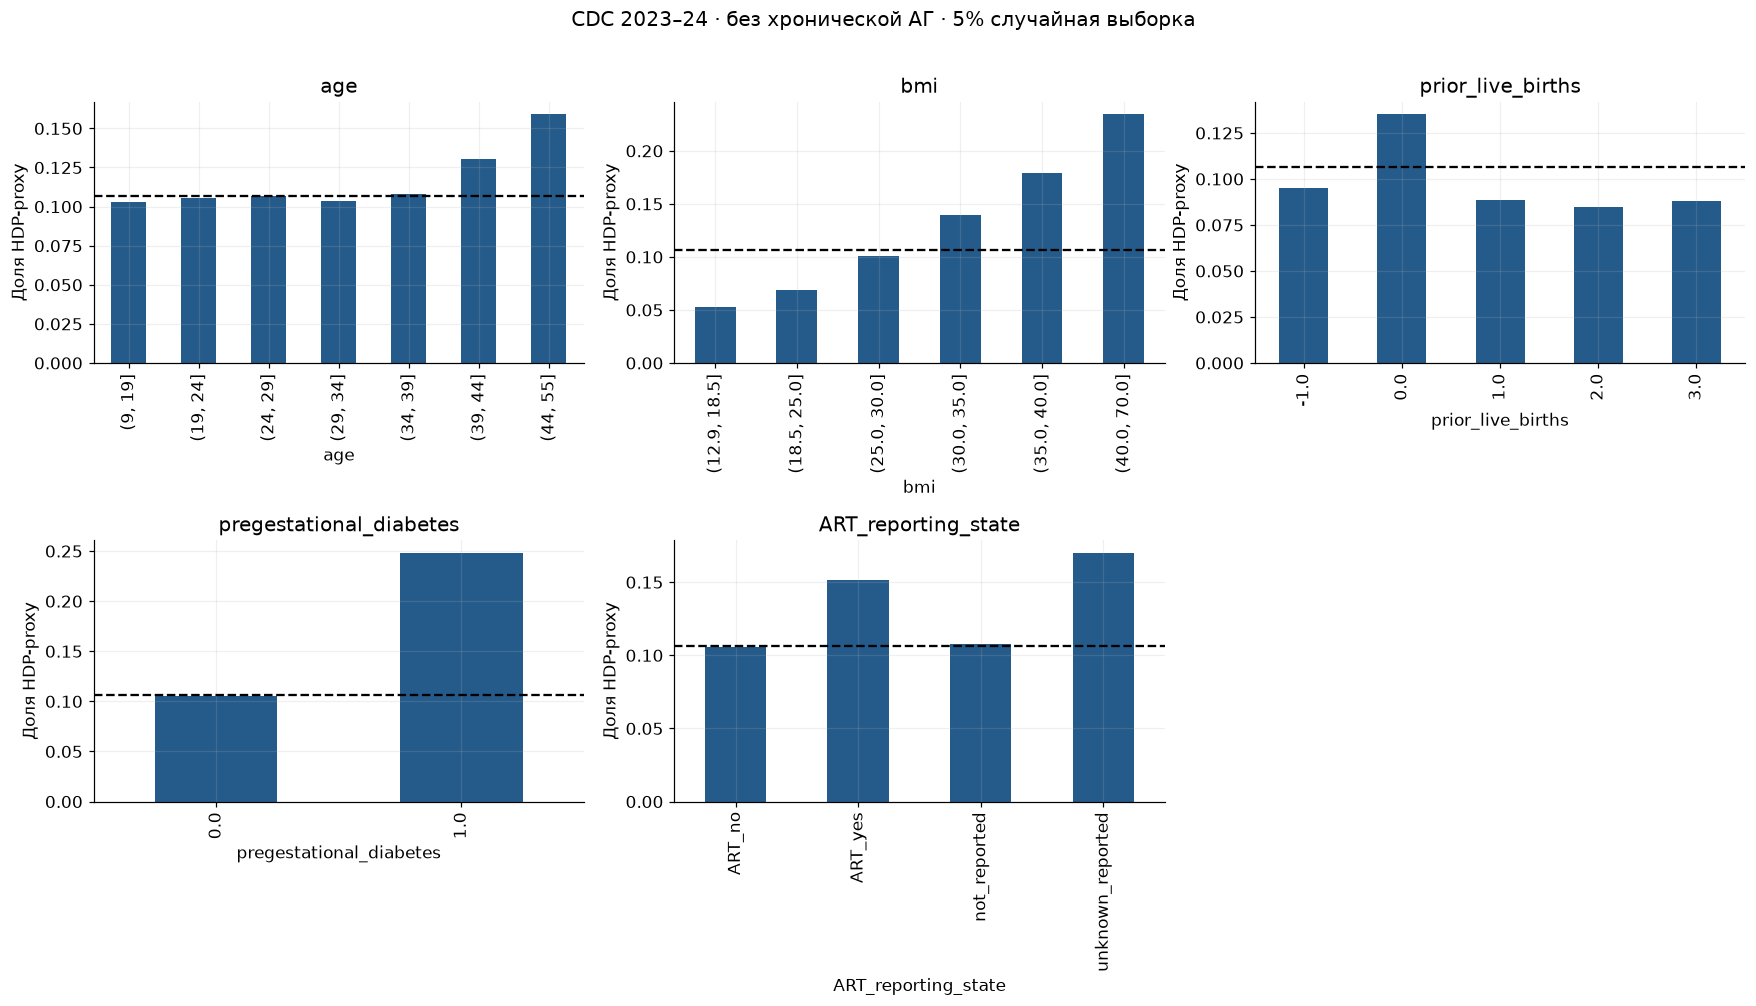

In [7]:
art_state=np.select([sample.art_source_reported.eq(0),sample.art_status_unknown_reported.eq(1),sample.rf_artec.eq(1),sample.rf_artec.eq(0)],["not_reported","unknown_reported","ART_yes","ART_no"],default="invalid")
bins = {"age":pd.cut(sample.mager,[9,19,24,29,34,39,44,55]), "bmi":pd.cut(sample.bmi,[12.9,18.5,25,30,35,40,70]), "prior_live_births":sample.prior_live_birth_count_cat.fillna(-1), "pregestational_diabetes":sample.rf_pdiab, "ART_reporting_state":pd.Series(art_state,index=sample.index)}
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes=axes.ravel()
for ax,(name,categories) in zip(axes,bins.items()):
    counts=sample.groupby(categories,observed=True).target_hdp_proxy.agg(["size","sum","mean"])
    display(counts.rename(columns={"size":"n","sum":"events","mean":"event_rate"}).assign(variable=name).round(4))
    counts["mean"].plot.bar(ax=ax,color=BLUE); ax.axhline(sample.target_hdp_proxy.mean(),ls="--",color="black")
    ax.set(xlabel=name,ylabel="Доля HDP-proxy",title=name)
axes[-1].axis("off"); fig.suptitle("CDC 2023–24 · без хронической АГ · 5% случайная выборка",y=1.01); plt.tight_layout(); plt.show()

## Одномерные OR и интервалы

,feature,n,or_unadjusted,ci_low,ci_high
0,rf_pdiab,337861,2.812,2.606,3.035
1,rf_ppterm,337861,1.582,1.505,1.662
2,rf_cesar,337861,0.935,0.906,0.964
3,no_prior_live_birth,336881,1.635,1.599,1.671
4,age_35_plus,337861,1.083,1.055,1.112
5,bmi_30_plus,330194,2.288,2.238,2.340
6,rf_artec,325970,1.514,1.409,1.628


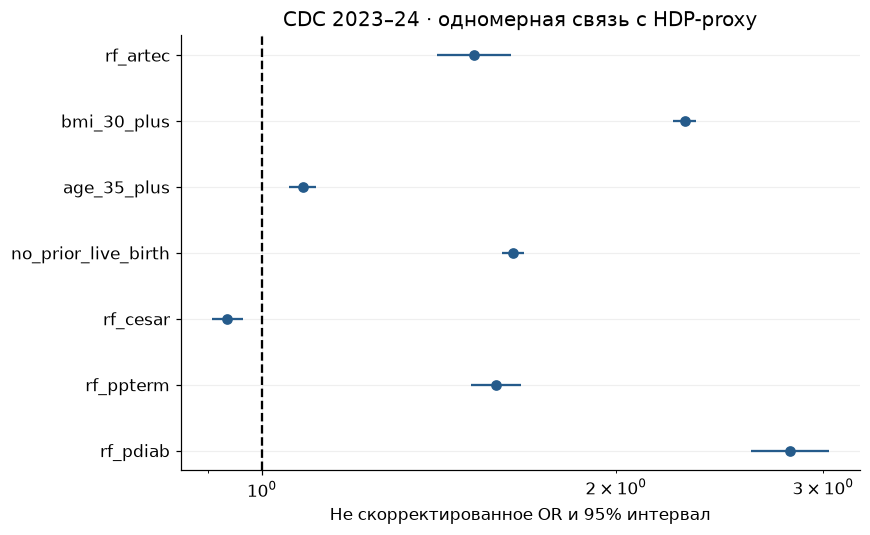

In [9]:
binary = ["rf_pdiab","rf_ppterm","rf_cesar","no_prior_live_birth","age_35_plus","bmi_30_plus","rf_artec"]
rows=[]
for feature in binary:
    part=sample.loc[sample[feature].isin([0,1]),[feature,"target_hdp_proxy"]]
    a=int(((part[feature]==1)&(part.target_hdp_proxy==1)).sum()); b=int(((part[feature]==1)&(part.target_hdp_proxy==0)).sum())
    c=int(((part[feature]==0)&(part.target_hdp_proxy==1)).sum()); d=int(((part[feature]==0)&(part.target_hdp_proxy==0)).sum())
    aa,bb,cc,dd=[v+.5 for v in [a,b,c,d]]
    log_or=np.log(aa*dd/(bb*cc)); se=np.sqrt(1/aa+1/bb+1/cc+1/dd)
    rows.append({"feature":feature,"n":len(part),"or_unadjusted":np.exp(log_or),"ci_low":np.exp(log_or-1.96*se),"ci_high":np.exp(log_or+1.96*se)})
association=pd.DataFrame(rows); display(association.round(3))
fig,ax=plt.subplots(figsize=(8,5))
ax.errorbar(association.or_unadjusted,association.feature,xerr=[association.or_unadjusted-association.ci_low,association.ci_high-association.or_unadjusted],fmt="o",color=BLUE)
ax.axvline(1,ls="--",color="black");ax.set(xscale="log",xlabel="Не скорректированное OR и 95% интервал",title="CDC 2023–24 · одномерная связь с HDP-proxy")
plt.tight_layout();plt.show()

OR получены из 2×2 таблиц в выборке и не являются независимыми скорректированными эффектами или рекомендацией по лечению. Коэффициенты штрафной сплайн-логистики отдельно как OR не публикуются: маски, one-hot категории и регуляризация не дают такой интерпретации. `PRIORTERM` смешивает разные исходы прошлых беременностей, включая потери и прерывания; он не является чистым числом выкидышей. `RF_ARTEC` доступен только после зачатия и при отчётности штата. Категории с очень малым числом событий трактуйте осторожно. Качество моделей и перестановочная важность оцениваются отдельно.